In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import joblib

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [2]:
DATA_PATH = Path("../data/processed/bloodmnist_preprocessed.npz")

with np.load(DATA_PATH) as data:

    X_test_rf = data["X_test"]
    X_test_cnn = data["X_test_standardized"]
    y_test = data["y_test"]
    class_names = data["class_names"].tolist()

print("Test images:", X_test_rf.shape)
print("Test labels:", y_test.shape)
print("Number of classes:", len(class_names))

Test images: (3420, 28, 28, 3)
Test labels: (3420,)
Number of classes: 8


In [4]:
X_test_rf = X_test_rf.reshape(
    X_test_rf.shape[0], -1
)

X_test_cnn = np.transpose(
    X_test_cnn,
    (0, 3, 1, 2)
).copy()

X_test_cnn_tensor = torch.from_numpy(
    X_test_cnn.astype(np.float32)
)

y_test_tensor = torch.from_numpy(
    y_test.astype(np.int64)
)

# DataLoader
test_dataset = TensorDataset(
    X_test_cnn_tensor,
    y_test_tensor
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("Random Forest input:", X_test_rf.shape)
print("CNN input:", X_test_cnn_tensor.shape)
print("Test batches:", len(test_loader))

Random Forest input: (3420, 2352)
CNN input: torch.Size([3420, 28, 3, 28])
Test batches: 27


In [5]:
class BloodCellCNN(nn.Module):

    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        x = self.classifier(x)
        return x


# load Random Forest
rf_model = joblib.load(
    Path("../models/random_forest_baseline.joblib")
)

# create CNN
cnn_model = BloodCellCNN(
    num_classes=len(class_names)
).to(device)

# load saved weights for cnn
cnn_checkpoint = torch.load(
    Path("../models/bloodcell_cnn_best.pth"),
    map_location=device,
    weights_only=True
)

cnn_model.load_state_dict(cnn_checkpoint)
cnn_model.eval()

print("Random Forest loaded successfully!")
print("CNN loaded successfully!")
print("CNN device:", next(cnn_model.parameters()).device)

c:\venvs\bloodcell\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.7.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\venvs\bloodcell\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.7.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Random Forest loaded successfully!
CNN loaded successfully!
CNN device: cuda:0


In [9]:
with np.load(DATA_PATH) as data:
    X_test_cnn_raw = data["X_test_standardized"]
    y_test = data["y_test"]

print("Original shape:", X_test_cnn_raw.shape)

if X_test_cnn_raw.shape[1] == 3:
    X_test_cnn = X_test_cnn_raw

elif X_test_cnn_raw.shape[-1] == 3:
    X_test_cnn = np.transpose(
        X_test_cnn_raw,
        (0, 3, 1, 2)
    )

else:
    raise ValueError("Unexpected image dimensions!")

X_test_cnn_tensor = torch.from_numpy(
    np.ascontiguousarray(X_test_cnn, dtype=np.float32)
)

y_test_tensor = torch.from_numpy(
    y_test.astype(np.int64)
)

test_dataset = TensorDataset(
    X_test_cnn_tensor,
    y_test_tensor
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("Corrected CNN shape:", X_test_cnn_tensor.shape)
print("Test batches:", len(test_loader))

Original shape: (3420, 28, 28, 3)
Corrected CNN shape: torch.Size([3420, 3, 28, 28])
Test batches: 27


In [10]:
y_test_pred_rf = rf_model.predict(X_test_rf)

y_test_pred_cnn = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = cnn_model(images)

        predictions = outputs.argmax(dim=1)

        y_test_pred_cnn.extend(
            predictions.cpu().numpy()
        )

y_test_pred_cnn = np.array(y_test_pred_cnn)

print("Random Forest predictions:", len(y_test_pred_rf))
print("CNN predictions:", len(y_test_pred_cnn))
print("Actual labels:", len(y_test))

Random Forest predictions: 3420
CNN predictions: 3420
Actual labels: 3420


In [11]:
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# Random Forest
print("========== RANDOM FOREST – TEST ==========")

print(
    classification_report(
        y_test,
        y_test_pred_rf,
        target_names=class_names,
        digits=3
    )
)

# CNN
print("\n========== CNN – TEST ==========")

print(
    classification_report(
        y_test,
        y_test_pred_cnn,
        target_names=class_names,
        digits=3
    )
)

========== RANDOM FOREST – TEST ==========
                                                                     precision    recall  f1-score   support

                                                           basophil      0.747     0.508     0.605       244
                                                         eosinophil      0.882     0.921     0.901       624
                                                       erythroblast      0.898     0.817     0.855       311
immature granulocytes(myelocytes, metamyelocytes and promyelocytes)      0.626     0.770     0.691       579
                                                         lymphocyte      0.840     0.819     0.829       243
                                                           monocyte      0.830     0.500     0.624       284
                                                         neutrophil      0.858     0.938     0.897       665
                                                           platelet      0.992     0

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

predictions = {
    "Random Forest": y_test_pred_rf,
    "CNN": y_test_pred_cnn
}

results = []

for model_name, predictions_array in predictions.items():

    results.append({
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_test,
            predictions_array
        ),

        "Macro Precision": precision_score(
            y_test,
            predictions_array,
            average="macro"
        ),

        "Macro Recall": recall_score(
            y_test,
            predictions_array,
            average="macro"
        ),

        "Macro F1": f1_score(
            y_test,
            predictions_array,
            average="macro"
        ),

        "Weighted F1": f1_score(
            y_test,
            predictions_array,
            average="weighted"
        )
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    REPORT_DIR / "final_model_comparison.csv",
    index=False
)

print("\nModel comparison saved successfully!")

        Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
Random Forest    0.8281           0.8341        0.7837    0.7995        0.824
          CNN    0.9257           0.9195        0.9126    0.9154        0.926

Model comparison saved successfully!


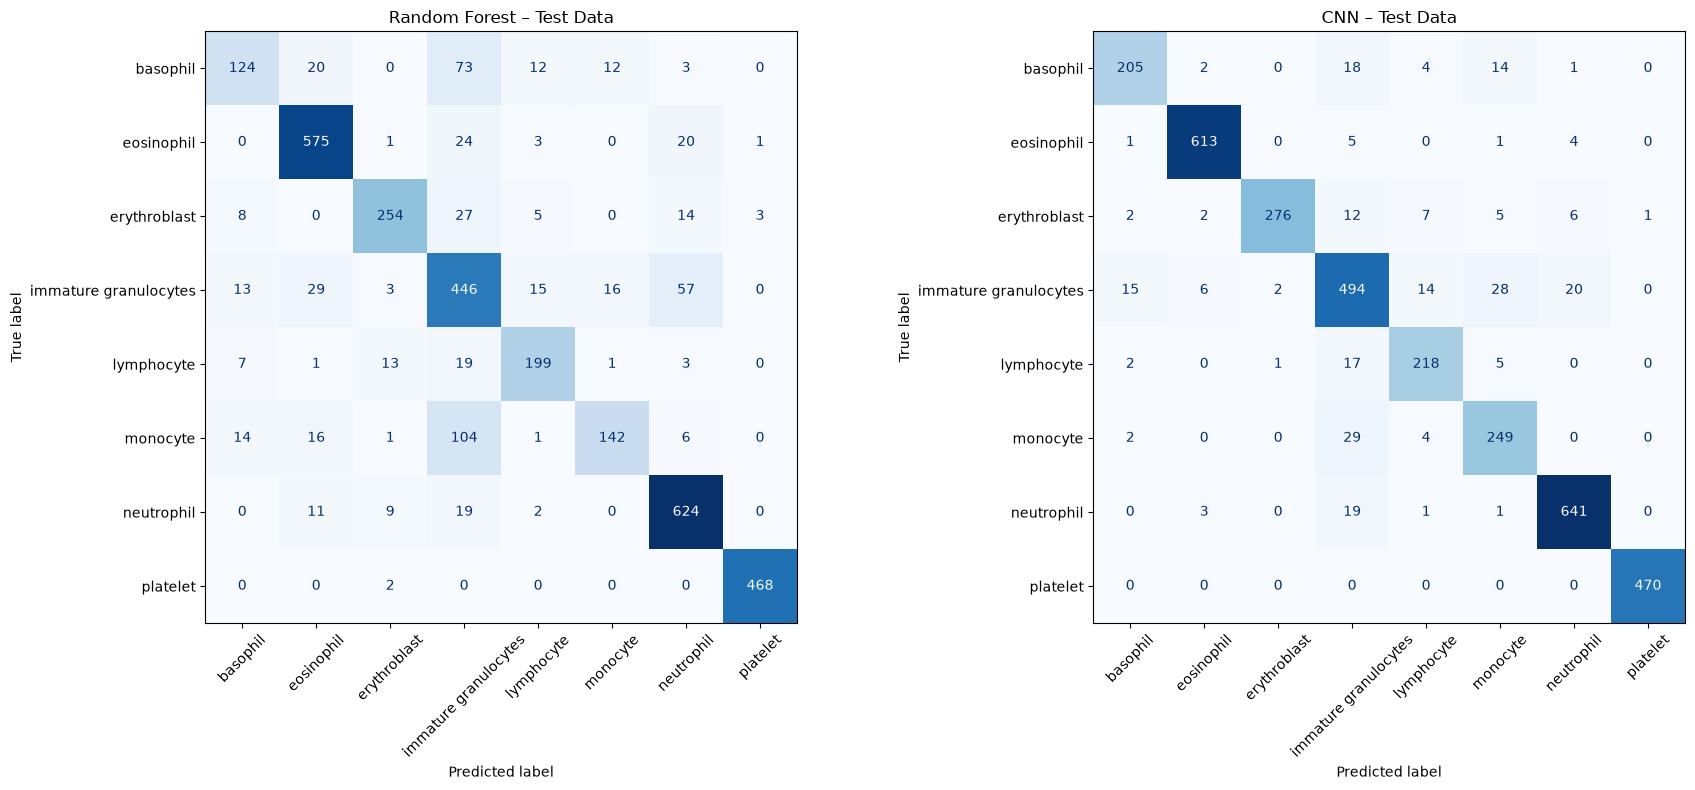

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

display_names = [
    str(name).split("(")[0].strip()
    for name in class_names
]

cm_rf = confusion_matrix(
    y_test,
    y_test_pred_rf,
    labels=np.arange(len(class_names))
)

cm_cnn = confusion_matrix(
    y_test,
    y_test_pred_cnn,
    labels=np.arange(len(class_names))
)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Random Forest
ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=display_names
).plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

axes[0].set_title("Random Forest – Test Data")

# CNN
ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=display_names
).plot(
    ax=axes[1],
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

axes[1].set_title("CNN – Test Data")

plt.tight_layout()

REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    REPORT_DIR / "final_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
pd.DataFrame(
    cm_rf,
    index=class_names,
    columns=class_names
).to_csv(REPORT_DIR / "random_forest_confusion_matrix.csv")

pd.DataFrame(
    cm_cnn,
    index=class_names,
    columns=class_names
).to_csv(REPORT_DIR / "cnn_confusion_matrix.csv")

print("Confusion matrices saved successfully!")

Confusion matrices saved successfully!
